# SOM-OT Warp — Generalization Benchmark
## Track B only (no anchor samples)

**Dataset**: Trussart / CytofRUV (FR-FCM-Z2L2) — 2 batches, 33 markers, ~8.6M cells  
**Methods**: SOM-OT Warp, ComBat, MMD-ResNet, (CytoNorm, cyCombine optional)

### Three experiments

| Exp | Fit on | Evaluate on | What it tests |
|-----|--------|-------------|---------------|
| **1a** | 40K cells (train split) | 10K held-out cells (test split) | Out-of-sample generalization |
| **1b** | All 50K cells | Same 10K test cells | Effect of more training data on the same held-out set |
| **2** | 50K cells (subsample) | Full dataset (~8.6M cells) | Scalability: can a small fit correct the full experiment? |

Experiment 1 tests whether the correction learned on a subset transfers to unseen cells, and whether adding more training data (including the test cells) improves quality on a fixed evaluation set.  
Experiment 2 tests whether a lightweight fit is sufficient to correct a massive dataset.

In [55]:
import sys, os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

warnings.filterwarnings('ignore')
%matplotlib inline
%load_ext autoreload
%autoreload 2

REPO = Path(os.environ.get('SOMOT_REPO', Path.cwd().resolve().parent))  # run from scripts/
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / 'scripts'))

from benchmark_public import (
    load_trussart, compute_all_metrics, per_marker_emd,
    run_somot, run_combat, run_mmdresnet
)
from somot_warp.sklearn_api import SOMOTWarpSKExact
print('Imports OK')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Imports OK


---
## 0. Configuration & Data Loading

In [56]:
DATA_DIR = os.environ.get('SOMOT_TRUSSART_DIR', str(REPO / 'data' / 'trussart'))
ANCHOR_BATCH = 'RUV1b'
N_SUBSAMPLE  = 50000     # total cells for experiments 1 & 2
N_TRAIN      = 40000     # train split for experiment 1
N_TEST       = 10000     # test split for experiment 1
SEED         = 42

# SOM-OT hyperparameters (shared across all experiments)
SOMOT_KWARGS = dict(
    anchor='A', output_scale='A',
    transform_kind='arcsinh', pca_components=None,
    som_grid=(8, 8), som_iters=8000,
    n_landmarks_total=1200,
    q_grid=np.array([0, 1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99, 100]),
    alpha_ot=0.7, alpha_warp=None,
    som_verbose=False,
)

In [57]:
# Load full dataset
X_full, y_batch_full, y_sample_full, y_celltype_full, markers = load_trussart(DATA_DIR)

# Drop Unassigned
keep = y_celltype_full != 'Unassigned'
X_full = X_full[keep]
y_batch_full = y_batch_full[keep]
y_sample_full = y_sample_full[keep]
y_celltype_full = y_celltype_full[keep]

print(f'Full dataset: {X_full.shape[0]:,} cells  ×  {len(markers)} markers')
print(f'Batches: {dict(zip(*np.unique(y_batch_full, return_counts=True)))}')
print(f'Cell types: {dict(zip(*np.unique(y_celltype_full, return_counts=True)))}')

  Loading cached data from <SOMOT_TRUSSART_DIR>/_cache_trussart.parquet
Full dataset: 8,611,858 cells  ×  33 markers
Batches: {'RUV1b': np.int64(5721104), 'RUV3b': np.int64(2890754)}
Cell types: {'A': np.int64(2665479), 'B': np.int64(3259600), 'C': np.int64(2674695), 'D': np.int64(12084)}


In [87]:
# ── Create the 50K subsample (balanced across batches) ──
rng = np.random.RandomState(SEED)
sub_idx = []
n_per_batch = N_SUBSAMPLE // len(np.unique(y_batch_full))
for b in np.unique(y_batch_full):
    idx = np.where(y_batch_full == b)[0]
    sub_idx.append(rng.choice(idx, min(n_per_batch, len(idx)), replace=False))
sub_idx = np.sort(np.concatenate(sub_idx))

X_50k        = X_full[sub_idx]
y_batch_50k  = y_batch_full[sub_idx]
y_ct_50k     = y_celltype_full[sub_idx]

# ── Split 50K into 40K train + 10K test (stratified by batch) ──
train_idx_local = []
test_idx_local  = []
n_train_per_batch = N_TRAIN // len(np.unique(y_batch_50k))
for b in np.unique(y_batch_50k):
    idx = np.where(y_batch_50k == b)[0]
    perm = rng.permutation(idx)
    train_idx_local.append(perm[:n_train_per_batch])
    test_idx_local.append(perm[n_train_per_batch:])
train_idx_local = np.sort(np.concatenate(train_idx_local))
test_idx_local  = np.sort(np.concatenate(test_idx_local))

X_train      = X_50k[train_idx_local]
y_batch_train = y_batch_50k[train_idx_local]
y_ct_train   = y_ct_50k[train_idx_local]

X_test       = X_50k[test_idx_local]
y_batch_test = y_batch_50k[test_idx_local]
y_ct_test    = y_ct_50k[test_idx_local]

# ── Full-dataset index complement (cells NOT in the 50K) ──
full_complement_mask = np.ones(len(X_full), dtype=bool)
full_complement_mask[sub_idx] = False

print(f'50K subsample: {len(X_50k):,}  (per batch: {n_per_batch:,})')
print(f'  Train: {len(X_train):,}  |  Test: {len(X_test):,}')
print(f'  Train batches: {dict(zip(*np.unique(y_batch_train, return_counts=True)))}')
print(f'  Test  batches: {dict(zip(*np.unique(y_batch_test, return_counts=True)))}')
print(f'Full dataset remaining (not in 50K): {full_complement_mask.sum():,}')

50K subsample: 50,000  (per batch: 25,000)
  Train: 40,000  |  Test: 10,000
  Train batches: {'RUV1b': np.int64(20000), 'RUV3b': np.int64(20000)}
  Test  batches: {'RUV1b': np.int64(5000), 'RUV3b': np.int64(5000)}
Full dataset remaining (not in 50K): 8,561,858


---
## Helper: fit + transform for each method

We need a helper that returns the **fitted model** so we can call `transform` on held-out data.

In [88]:
def fit_somot(X_fit, y_fit):
    """Fit SOM-OT and return the model."""
    model = SOMOTWarpSKExact(**SOMOT_KWARGS)
    y_mapped = np.where(y_fit == ANCHOR_BATCH, 'A', 'B')
    model.fit(X_fit, y_mapped)
    return model

def transform_somot(model, X, y_batch):
    """Transform data with a fitted SOM-OT model."""
    y_mapped = np.where(y_batch == ANCHOR_BATCH, 'A', 'B')
    return model.transform(X, y_mapped)


def fit_transform_combat(X_fit, y_fit):
    """ComBat: no separate fit/transform — must refit on eval data.
    Returns corrected X (ComBat has no stored model for OOS transform)."""
    from inmoose.pycombat import pycombat_norm
    X_corr = pycombat_norm(X_fit.T, list(y_fit))
    return np.asarray(X_corr.T, dtype=np.float32)


def fit_mmdresnet(X_fit, y_fit):
    """Fit MMD-ResNet models (one per non-anchor batch). Returns dict of models."""
    import torch
    import torch.nn as nn
    import torch.optim as optim

    class ResBlock(nn.Module):
        def __init__(self, dim):
            super().__init__()
            self.fc1 = nn.Linear(dim, dim)
            self.fc2 = nn.Linear(dim, dim)
            self.bn1 = nn.BatchNorm1d(dim)
            self.bn2 = nn.BatchNorm1d(dim)
        def forward(self, x):
            r = torch.relu(self.bn1(self.fc1(x)))
            r = self.bn2(self.fc2(r))
            return x + r

    class MMDResNet(nn.Module):
        def __init__(self, dim, n_blocks=3):
            super().__init__()
            self.blocks = nn.Sequential(*[ResBlock(dim) for _ in range(n_blocks)])
        def forward(self, x):
            return self.blocks(x)

    def mmd_rbf(x, y, sigma=1.0):
        xx = torch.cdist(x, x).pow(2)
        yy = torch.cdist(y, y).pow(2)
        xy = torch.cdist(x, y).pow(2)
        return torch.exp(-xx/(2*sigma**2)).mean() + torch.exp(-yy/(2*sigma**2)).mean() - 2*torch.exp(-xy/(2*sigma**2)).mean()

    batches = np.unique(y_fit)
    anchor_mask = y_fit == ANCHOR_BATCH
    X_anchor = X_fit[anchor_mask].astype(np.float32)
    target_t = torch.tensor(X_anchor, dtype=torch.float32)
    dim = X_fit.shape[1]

    models = {}
    for b in batches:
        if b == ANCHOR_BATCH:
            continue
        source = X_fit[y_fit == b].astype(np.float32)
        source_t = torch.tensor(source, dtype=torch.float32)
        model = MMDResNet(dim, n_blocks=3)
        optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-2)
        model.train()
        for epoch in range(200):
            idx_s = np.random.choice(len(source), min(1000, len(source)), replace=False)
            idx_t = np.random.choice(len(X_anchor), min(1000, len(X_anchor)), replace=False)
            out = model(source_t[idx_s])
            loss = mmd_rbf(out, target_t[idx_t])
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.eval()
        models[b] = model
    return models

def transform_mmdresnet(models, X, y_batch, chunk_size=500_000):
    """Transform data with fitted MMD-ResNet models. Chunks large arrays to avoid OOM."""
    import torch
    X_corr = X.copy().astype(np.float32)
    for b, model in models.items():
        mask = np.where(y_batch == b)[0]
        # Process in chunks to handle millions of cells
        for start in range(0, len(mask), chunk_size):
            idx = mask[start:start + chunk_size]
            with torch.no_grad():
                X_corr[idx] = model(torch.tensor(X[idx], dtype=torch.float32)).numpy()
    return X_corr

print('Helpers defined.')

Helpers defined.


In [89]:
def metrics_row(label, d):
    """Extract a flat dict from a metrics result."""
    return {
        'Setting': label,
        'kNN Entropy ↑': d.get('knn_entropy', np.nan),
        'iLISI ↑':       d.get('knn_ilisi', np.nan),
        'Sil. Batch ↓':  d.get('silhouette_batch', np.nan),
        'Sil. Bio ↑':    d.get('silhouette_bio', np.nan),
        'Graph Conn. ↑': d.get('graph_connectivity', np.nan),
        'Median EMD ↓':  d.get('per_marker_emd', {}).get('median_EMD', np.nan),
        'Mean EMD ↓':    d.get('per_marker_emd', {}).get('mean_EMD', np.nan),
    }

# Store all results for final comparison
ALL_ROWS = []

---
# Experiment 1a: Fit on 40K train → Evaluate on 10K held-out test

Tests **out-of-sample generalization**: does the learned correction transfer to cells the model has never seen?

In [90]:
print(f'Computing uncorrected baseline on TEST split ({len(X_test):,} cells)...')
metrics_test_before = compute_all_metrics(X_test, y_batch_test, bio_labels=y_ct_test, markers=markers)
ALL_ROWS.append(metrics_row('Exp1a — Uncorrected (test)', metrics_test_before))
print(f"  kNN Entropy: {metrics_test_before['knn_entropy']:.4f}")
print(f"  Median EMD:  {metrics_test_before['per_marker_emd']['median_EMD']:.4f}")

Computing uncorrected baseline on TEST split (10,000 cells)...
  kNN Entropy: 0.7103
  Median EMD:  3.5949


In [91]:
# ── SOM-OT Warp: fit on train, transform test ──
print('Exp1a — SOM-OT: fit on 40K train...')
t0 = time.perf_counter()
model_somot_1a = fit_somot(X_train, y_batch_train)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
X_test_somot_1a = transform_somot(model_somot_1a, X_test, y_batch_test)
t_transform = time.perf_counter() - t0

metrics_somot_1a = compute_all_metrics(X_test_somot_1a, y_batch_test, bio_labels=y_ct_test, markers=markers)
ALL_ROWS.append(metrics_row('Exp1a — SOM-OT (test)', metrics_somot_1a))
print(f'  Fit: {t_fit:.1f}s  |  Transform: {t_transform:.1f}s')
print(f"  kNN Entropy: {metrics_somot_1a['knn_entropy']:.4f}  |  Median EMD: {metrics_somot_1a['per_marker_emd']['median_EMD']:.4f}")

Exp1a — SOM-OT: fit on 40K train...
  Fit: 2.2s  |  Transform: 0.2s
  kNN Entropy: 0.9173  |  Median EMD: 1.1045


In [92]:
# ── ComBat: no OOS transform — must refit on test data ──
# ComBat corrects in-place; it has no stored model. We apply it to the test split directly.
# This is how ComBat is used in practice — it operates on the data it's given.
print('Exp1a — ComBat on test split...')
t0 = time.perf_counter()
X_test_combat_1a = fit_transform_combat(X_test.copy(), y_batch_test)
t_cb = time.perf_counter() - t0

metrics_combat_1a = compute_all_metrics(X_test_combat_1a, y_batch_test, bio_labels=y_ct_test, markers=markers)
ALL_ROWS.append(metrics_row('Exp1a — ComBat (test)', metrics_combat_1a))
print(f'  Time: {t_cb:.1f}s')
print(f"  kNN Entropy: {metrics_combat_1a['knn_entropy']:.4f}  |  Median EMD: {metrics_combat_1a['per_marker_emd']['median_EMD']:.4f}")

Exp1a — ComBat on test split...
  Time: 0.0s
  kNN Entropy: 0.7487  |  Median EMD: 2.2814


In [93]:
# ── MMD-ResNet: fit on train, transform test ──
print('Exp1a — MMD-ResNet: fit on 40K train...')
t0 = time.perf_counter()
models_mmd_1a = fit_mmdresnet(X_train, y_batch_train)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
X_test_mmd_1a = transform_mmdresnet(models_mmd_1a, X_test, y_batch_test)
t_transform = time.perf_counter() - t0

metrics_mmd_1a = compute_all_metrics(X_test_mmd_1a, y_batch_test, bio_labels=y_ct_test, markers=markers)
ALL_ROWS.append(metrics_row('Exp1a — MMD-ResNet (test)', metrics_mmd_1a))
print(f'  Fit: {t_fit:.1f}s  |  Transform: {t_transform:.1f}s')
print(f"  kNN Entropy: {metrics_mmd_1a['knn_entropy']:.4f}  |  Median EMD: {metrics_mmd_1a['per_marker_emd']['median_EMD']:.4f}")

Exp1a — MMD-ResNet: fit on 40K train...
  Fit: 4.5s  |  Transform: 0.0s
  kNN Entropy: 0.6652  |  Median EMD: 3.4429


---
# Experiment 1b: Fit on all 50K → Evaluate on same 10K test cells

Same held-out evaluation set as Exp1a, but the model is trained on **all 50K cells** (which includes the 10K test cells).  
The gap between 1a and 1b measures how much **more training data** (and mild data leakage) improves correction quality on a fixed evaluation set.

In [65]:
# Exp1b evaluates on the SAME 10K test cells as Exp1a.
# The uncorrected baseline is therefore identical — just reuse it.
print(f'Exp1b uncorrected baseline = Exp1a baseline (same {len(X_test):,} test cells)')
print(f"  kNN Entropy: {metrics_test_before['knn_entropy']:.4f}")
print(f"  Median EMD:  {metrics_test_before['per_marker_emd']['median_EMD']:.4f}")
# (No new row — already in ALL_ROWS from Exp1a)

Exp1b uncorrected baseline = Exp1a baseline (same 10,000 test cells)
  kNN Entropy: 0.7103
  Median EMD:  3.5949


In [66]:
# ── SOM-OT Warp: fit on all 50K, evaluate on 10K test cells ──
print('Exp1b — SOM-OT: fit on 50K, evaluate on 10K test...')
t0 = time.perf_counter()
model_somot_1b = fit_somot(X_50k, y_batch_50k)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
X_test_somot_1b = transform_somot(model_somot_1b, X_test, y_batch_test)
t_transform = time.perf_counter() - t0

metrics_somot_1b = compute_all_metrics(X_test_somot_1b, y_batch_test, bio_labels=y_ct_test, markers=markers)
ALL_ROWS.append(metrics_row('Exp1b — SOM-OT (50K-fit, test)', metrics_somot_1b))
print(f'  Fit: {t_fit:.1f}s  |  Transform: {t_transform:.1f}s')
print(f"  kNN Entropy: {metrics_somot_1b['knn_entropy']:.4f}  |  Median EMD: {metrics_somot_1b['per_marker_emd']['median_EMD']:.4f}")

Exp1b — SOM-OT: fit on 50K, evaluate on 10K test...
  Fit: 2.5s  |  Transform: 0.2s
  kNN Entropy: 0.9004  |  Median EMD: 0.6627


In [67]:
# ── ComBat: fit on all 50K, extract correction for 10K test cells ──
# ComBat has no stored model — we must correct the full 50K and then pull out the test rows.
print('Exp1b — ComBat on 50K (evaluating test cells only)...')
t0 = time.perf_counter()
X_50k_combat_1b = fit_transform_combat(X_50k.copy(), y_batch_50k)
t_cb = time.perf_counter() - t0

# Extract the 10K test cell rows from the corrected 50K
X_test_combat_1b = X_50k_combat_1b[test_idx_local]

metrics_combat_1b = compute_all_metrics(X_test_combat_1b, y_batch_test, bio_labels=y_ct_test, markers=markers)
ALL_ROWS.append(metrics_row('Exp1b — ComBat (50K-fit, test)', metrics_combat_1b))
print(f'  Time: {t_cb:.1f}s')
print(f"  kNN Entropy: {metrics_combat_1b['knn_entropy']:.4f}  |  Median EMD: {metrics_combat_1b['per_marker_emd']['median_EMD']:.4f}")

Exp1b — ComBat on 50K (evaluating test cells only)...
  Time: 0.1s
  kNN Entropy: 0.7408  |  Median EMD: 2.2014


In [68]:
# ── MMD-ResNet: fit on all 50K, transform 10K test ──
print('Exp1b — MMD-ResNet: fit on 50K, evaluate on 10K test...')
t0 = time.perf_counter()
models_mmd_1b = fit_mmdresnet(X_50k, y_batch_50k)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
X_test_mmd_1b = transform_mmdresnet(models_mmd_1b, X_test, y_batch_test)
t_transform = time.perf_counter() - t0

metrics_mmd_1b = compute_all_metrics(X_test_mmd_1b, y_batch_test, bio_labels=y_ct_test, markers=markers)
ALL_ROWS.append(metrics_row('Exp1b — MMD-ResNet (50K-fit, test)', metrics_mmd_1b))
print(f'  Fit: {t_fit:.1f}s  |  Transform: {t_transform:.1f}s')
print(f"  kNN Entropy: {metrics_mmd_1b['knn_entropy']:.4f}  |  Median EMD: {metrics_mmd_1b['per_marker_emd']['median_EMD']:.4f}")

Exp1b — MMD-ResNet: fit on 50K, evaluate on 10K test...
  Fit: 4.4s  |  Transform: 0.0s
  kNN Entropy: 0.6201  |  Median EMD: 3.8648


---
### Experiment 1 Summary: 40K-fit vs 50K-fit (same 10K test cells)

Both Exp1a and Exp1b evaluate on the **same 10K test cells**. The only difference is the training set:
- **Exp1a**: fit on 40K (test cells excluded)
- **Exp1b**: fit on 50K (test cells included in training)

In [69]:
exp1_df = pd.DataFrame(ALL_ROWS).round(4)
print('═' * 90)
print('EXPERIMENT 1: 40K-fit (Exp1a) vs 50K-fit (Exp1b) — evaluated on same 10K test cells')
print('═' * 90)
exp1_df

══════════════════════════════════════════════════════════════════════════════════════════
EXPERIMENT 1: 40K-fit (Exp1a) vs 50K-fit (Exp1b) — evaluated on same 10K test cells
══════════════════════════════════════════════════════════════════════════════════════════


,Setting,kNN Entropy ↑,iLISI ↑,Sil. Batch ↓,Sil. Bio ↑,Graph Conn. ↑,Median EMD ↓,Mean EMD ↓
0,Exp1a — Uncorrected (test),0.7103,1.5715,0.0188,-0.0728,0.7872,3.5949,11.5614
1,Exp1a — SOM-OT (test),0.9173,1.8311,0.0011,-0.0326,0.7747,1.1045,2.5046
2,Exp1a — ComBat (test),0.7487,1.6104,0.0022,-0.0152,0.7885,2.2814,6.0050
3,Exp1a — MMD-ResNet (test),0.6144,1.4739,0.0212,-0.0715,0.7880,3.9026,11.7043
4,"Exp1b — SOM-OT (50K-fit, test)",0.9004,1.8072,0.0016,-0.0190,0.7750,0.6627,2.3146
5,"Exp1b — ComBat (50K-fit, test)",0.7408,1.5947,0.0018,-0.0271,0.7889,2.2014,5.4782
6,"Exp1b — MMD-ResNet (50K-fit, test)",0.6201,1.4734,0.0190,-0.0762,0.7880,3.8648,11.7064


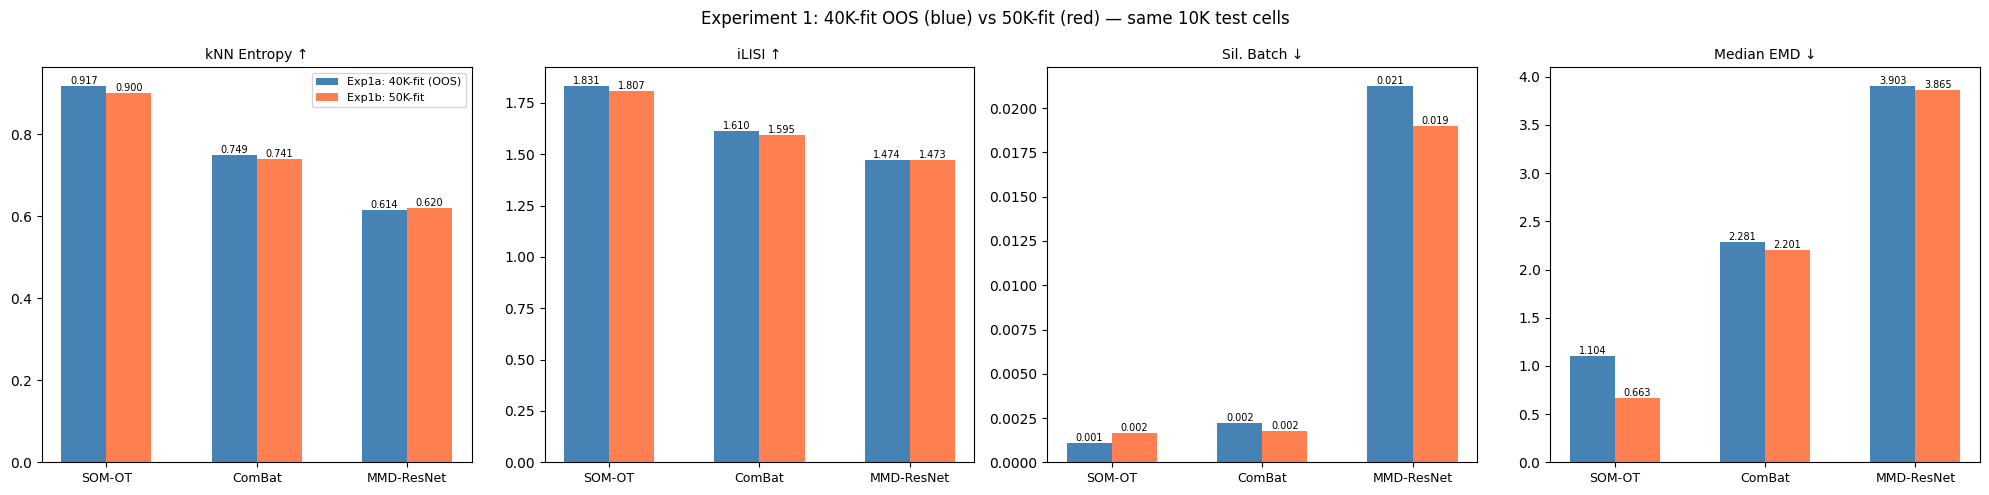

In [70]:
# ── Generalization gap plot: Exp1a (40K-fit) vs Exp1b (50K-fit) on same test cells ──
methods_exp1 = ['SOM-OT', 'ComBat', 'MMD-ResNet']
metric_keys = ['kNN Entropy ↑', 'iLISI ↑', 'Sil. Batch ↓', 'Median EMD ↓']

fig, axes = plt.subplots(1, len(metric_keys), figsize=(5 * len(metric_keys), 5))

for ax, mk in zip(axes, metric_keys):
    x = np.arange(len(methods_exp1))
    width = 0.3

    vals_1a = []  # 40K-fit, OOS test
    vals_1b = []  # 50K-fit, same test cells
    for m_name in methods_exp1:
        row_1a = [r for r in ALL_ROWS if m_name in r['Setting'] and 'Exp1a' in r['Setting']
                  and 'Uncorrected' not in r['Setting']]
        row_1b = [r for r in ALL_ROWS if m_name in r['Setting'] and 'Exp1b' in r['Setting']
                  and 'Uncorrected' not in r['Setting']]
        vals_1a.append(row_1a[0][mk] if row_1a else np.nan)
        vals_1b.append(row_1b[0][mk] if row_1b else np.nan)

    bars1 = ax.bar(x - width/2, vals_1a, width, label='Exp1a: 40K-fit (OOS)', color='steelblue')
    bars2 = ax.bar(x + width/2, vals_1b, width, label='Exp1b: 50K-fit', color='coral')

    ax.set_xticks(x)
    ax.set_xticklabels(methods_exp1, fontsize=9)
    ax.set_title(mk, fontsize=10)
    if ax == axes[0]:
        ax.legend(fontsize=8)

    # Add value labels
    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        if not np.isnan(h):
            ax.text(bar.get_x() + bar.get_width()/2, h, f'{h:.3f}',
                    ha='center', va='bottom', fontsize=7)

plt.suptitle('Experiment 1: 40K-fit OOS (blue) vs 50K-fit (red) — same 10K test cells', fontsize=12)
plt.tight_layout()
plt.show()

---
# Experiment 2: Fit on 50K subsample → Transform & evaluate on full dataset (~8.6M cells)

Tests **scalability**: can a model trained on 50K cells correct the full ~8.6M cell dataset?  
This is the practical use case — fit on a manageable subset, correct everything.

**Metrics strategy:**
- **EMD** is computed on the **full** corrected dataset (univariate, fast)
- **kNN-based metrics** (entropy, iLISI, silhouette, graph connectivity) are computed on a
  random subsample of the corrected output, since kNN on 8.6M cells is infeasible

In [71]:
N_KNN_SUB = 50000  # subsample size for kNN-based metrics (entropy, iLISI, silhouette, graph conn.)

def compute_full_metrics(X_full_corr, y_batch_full, y_ct_full, markers, n_knn_sub=N_KNN_SUB):
    """
    Compute metrics on the full corrected dataset:
    - EMD: computed on ALL cells (univariate per marker, fast)
    - kNN-based: computed on a balanced random subsample (kNN on 8.6M is infeasible)
    """
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA

    # ── Full-dataset EMD ──
    emd_result = per_marker_emd(X_full_corr, y_batch_full, markers)

    # ── Subsample for kNN metrics ──
    rng_sub = np.random.RandomState(99)
    sub_idx = []
    n_per_b = n_knn_sub // len(np.unique(y_batch_full))
    for b in np.unique(y_batch_full):
        idx = np.where(y_batch_full == b)[0]
        sub_idx.append(rng_sub.choice(idx, min(n_per_b, len(idx)), replace=False))
    sub_idx = np.sort(np.concatenate(sub_idx))

    X_sub = X_full_corr[sub_idx]
    y_b_sub = y_batch_full[sub_idx]
    y_ct_sub = y_ct_full[sub_idx]

    knn_metrics = compute_all_metrics(X_sub, y_b_sub, bio_labels=y_ct_sub, markers=markers)

    # Merge: use kNN-based from subsample, EMD from full dataset
    result = {k: v for k, v in knn_metrics.items() if k != 'per_marker_emd'}
    result['per_marker_emd'] = emd_result
    return result

print(f'Full dataset: {len(X_full):,} cells')
print(f'kNN subsample size: {N_KNN_SUB:,}')

Full dataset: 8,611,858 cells
kNN subsample size: 50,000


In [72]:
print(f'Computing uncorrected baseline on FULL dataset ({len(X_full):,} cells)...')
print(f'  EMD: all cells  |  kNN metrics: {N_KNN_SUB:,} subsample')
t0 = time.perf_counter()
metrics_full_before = compute_full_metrics(X_full, y_batch_full, y_celltype_full, markers)
t_base = time.perf_counter() - t0

ALL_ROWS.append(metrics_row('Exp2 — Uncorrected (full)', metrics_full_before))
print(f'  Time: {t_base:.1f}s')
print(f"  kNN Entropy: {metrics_full_before['knn_entropy']:.4f}")
print(f"  Median EMD:  {metrics_full_before['per_marker_emd']['median_EMD']:.4f}")

Computing uncorrected baseline on FULL dataset (8,611,858 cells)...
  EMD: all cells  |  kNN metrics: 50,000 subsample
  Time: 77.9s
  kNN Entropy: 0.6441
  Median EMD:  2.8338


In [73]:
# ── SOM-OT Warp: reuse model trained on 50K (model_somot_1b), transform FULL dataset ──
print(f'Exp2 — SOM-OT: transform full dataset ({len(X_full):,} cells) using 50K-trained model...')
t0 = time.perf_counter()
X_full_somot_2 = transform_somot(model_somot_1b, X_full, y_batch_full)
t_transform = time.perf_counter() - t0
print(f'  Transform time: {t_transform:.1f}s')

print('  Computing metrics (EMD on full, kNN on subsample)...')
t0 = time.perf_counter()
metrics_somot_2 = compute_full_metrics(X_full_somot_2, y_batch_full, y_celltype_full, markers)
t_metrics = time.perf_counter() - t0

ALL_ROWS.append(metrics_row('Exp2 — SOM-OT (full, 50K-fit)', metrics_somot_2))
print(f'  Metrics time: {t_metrics:.1f}s')
print(f"  kNN Entropy: {metrics_somot_2['knn_entropy']:.4f}  |  Median EMD: {metrics_somot_2['per_marker_emd']['median_EMD']:.4f}")

Exp2 — SOM-OT: transform full dataset (8,611,858 cells) using 50K-trained model...
  Transform time: 64.7s
  Computing metrics (EMD on full, kNN on subsample)...
  Metrics time: 78.4s
  kNN Entropy: 0.8530  |  Median EMD: 0.5541


In [74]:
# ── ComBat: must refit on full dataset (no OOS transform capability) ──
print(f'Exp2 — ComBat: refit on full dataset ({len(X_full):,} cells)...')
print('  NOTE: ComBat has no stored model — it must process all data at once.')
t0 = time.perf_counter()
X_full_combat_2 = fit_transform_combat(X_full.copy(), y_batch_full)
t_cb = time.perf_counter() - t0
print(f'  ComBat time: {t_cb:.1f}s')

print('  Computing metrics (EMD on full, kNN on subsample)...')
t0 = time.perf_counter()
metrics_combat_2 = compute_full_metrics(X_full_combat_2, y_batch_full, y_celltype_full, markers)
t_metrics = time.perf_counter() - t0

ALL_ROWS.append(metrics_row('Exp2 — ComBat (full, refit)', metrics_combat_2))
print(f'  Metrics time: {t_metrics:.1f}s')
print(f"  kNN Entropy: {metrics_combat_2['knn_entropy']:.4f}  |  Median EMD: {metrics_combat_2['per_marker_emd']['median_EMD']:.4f}")

Exp2 — ComBat: refit on full dataset (8,611,858 cells)...
  NOTE: ComBat has no stored model — it must process all data at once.
  ComBat time: 21.2s
  Computing metrics (EMD on full, kNN on subsample)...
  Metrics time: 75.7s
  kNN Entropy: 0.5211  |  Median EMD: 3.5540


In [75]:
# ── MMD-ResNet: reuse models trained on 50K, transform FULL dataset ──
print(f'Exp2 — MMD-ResNet: transform full dataset ({len(X_full):,} cells) using 50K-trained models...')
t0 = time.perf_counter()
X_full_mmd_2 = transform_mmdresnet(models_mmd_1b, X_full, y_batch_full)
t_transform = time.perf_counter() - t0
print(f'  Transform time: {t_transform:.1f}s')

print('  Computing metrics (EMD on full, kNN on subsample)...')
t0 = time.perf_counter()
metrics_mmd_2 = compute_full_metrics(X_full_mmd_2, y_batch_full, y_celltype_full, markers)
t_metrics = time.perf_counter() - t0

ALL_ROWS.append(metrics_row('Exp2 — MMD-ResNet (full, 50K-fit)', metrics_mmd_2))
print(f'  Metrics time: {t_metrics:.1f}s')
print(f"  kNN Entropy: {metrics_mmd_2['knn_entropy']:.4f}  |  Median EMD: {metrics_mmd_2['per_marker_emd']['median_EMD']:.4f}")

Exp2 — MMD-ResNet: transform full dataset (8,611,858 cells) using 50K-trained models...
  Transform time: 0.9s
  Computing metrics (EMD on full, kNN on subsample)...
  Metrics time: 80.6s
  kNN Entropy: 0.5387  |  Median EMD: 3.2439


---
# Combined Results

In [76]:
results_df = pd.DataFrame(ALL_ROWS)
# Round numeric columns
for c in results_df.columns:
    if results_df[c].dtype in [float, np.float64]:
        results_df[c] = results_df[c].round(4)

print('═' * 100)
print('ALL EXPERIMENTS — COMBINED RESULTS')
print('═' * 100)
results_df

════════════════════════════════════════════════════════════════════════════════════════════════════
ALL EXPERIMENTS — COMBINED RESULTS
════════════════════════════════════════════════════════════════════════════════════════════════════


,Setting,kNN Entropy ↑,iLISI ↑,Sil. Batch ↓,Sil. Bio ↑,Graph Conn. ↑,Median EMD ↓,Mean EMD ↓
0,Exp1a — Uncorrected (test),0.7103,1.5715,0.0188,-0.0728,0.7872,3.5949,11.5614
1,Exp1a — SOM-OT (test),0.9173,1.8311,0.0011,-0.0326,0.7747,1.1045,2.5046
2,Exp1a — ComBat (test),0.7487,1.6104,0.0022,-0.0152,0.7885,2.2814,6.0050
3,Exp1a — MMD-ResNet (test),0.6144,1.4739,0.0212,-0.0715,0.7880,3.9026,11.7043
4,"Exp1b — SOM-OT (50K-fit, test)",0.9004,1.8072,0.0016,-0.0190,0.7750,0.6627,2.3146
5,"Exp1b — ComBat (50K-fit, test)",0.7408,1.5947,0.0018,-0.0271,0.7889,2.2014,5.4782
6,"Exp1b — MMD-ResNet (50K-fit, test)",0.6201,1.4734,0.0190,-0.0762,0.7880,3.8648,11.7064
7,Exp2 — Uncorrected (full),0.6441,1.4981,0.0179,-0.1245,0.7678,2.8338,11.2424
8,"Exp2 — SOM-OT (full, 50K-fit)",0.8530,1.7375,0.0017,-0.1008,0.7673,0.5541,2.1402
9,"Exp2 — ComBat (full, refit)",0.5211,1.3956,0.0034,-0.1155,0.7639,3.5540,5.6025


In [77]:
# ── Grand comparison: SOM-OT across all 3 settings ──
somot_rows = [r for r in ALL_ROWS if 'SOM-OT' in r['Setting']]
somot_df = pd.DataFrame(somot_rows)
for c in somot_df.columns:
    if somot_df[c].dtype in [float, np.float64]:
        somot_df[c] = somot_df[c].round(4)

print('═' * 80)
print('SOM-OT Warp: GENERALIZATION ACROSS ALL SETTINGS')
print('═' * 80)
somot_df

════════════════════════════════════════════════════════════════════════════════
SOM-OT Warp: GENERALIZATION ACROSS ALL SETTINGS
════════════════════════════════════════════════════════════════════════════════


,Setting,kNN Entropy ↑,iLISI ↑,Sil. Batch ↓,Sil. Bio ↑,Graph Conn. ↑,Median EMD ↓,Mean EMD ↓
0,Exp1a — SOM-OT (test),0.9173,1.8311,0.0011,-0.0326,0.7747,1.1045,2.5046
1,"Exp1b — SOM-OT (50K-fit, test)",0.9004,1.8072,0.0016,-0.0190,0.7750,0.6627,2.3146
2,"Exp2 — SOM-OT (full, 50K-fit)",0.8530,1.7375,0.0017,-0.1008,0.7673,0.5541,2.1402


---
## Visualization

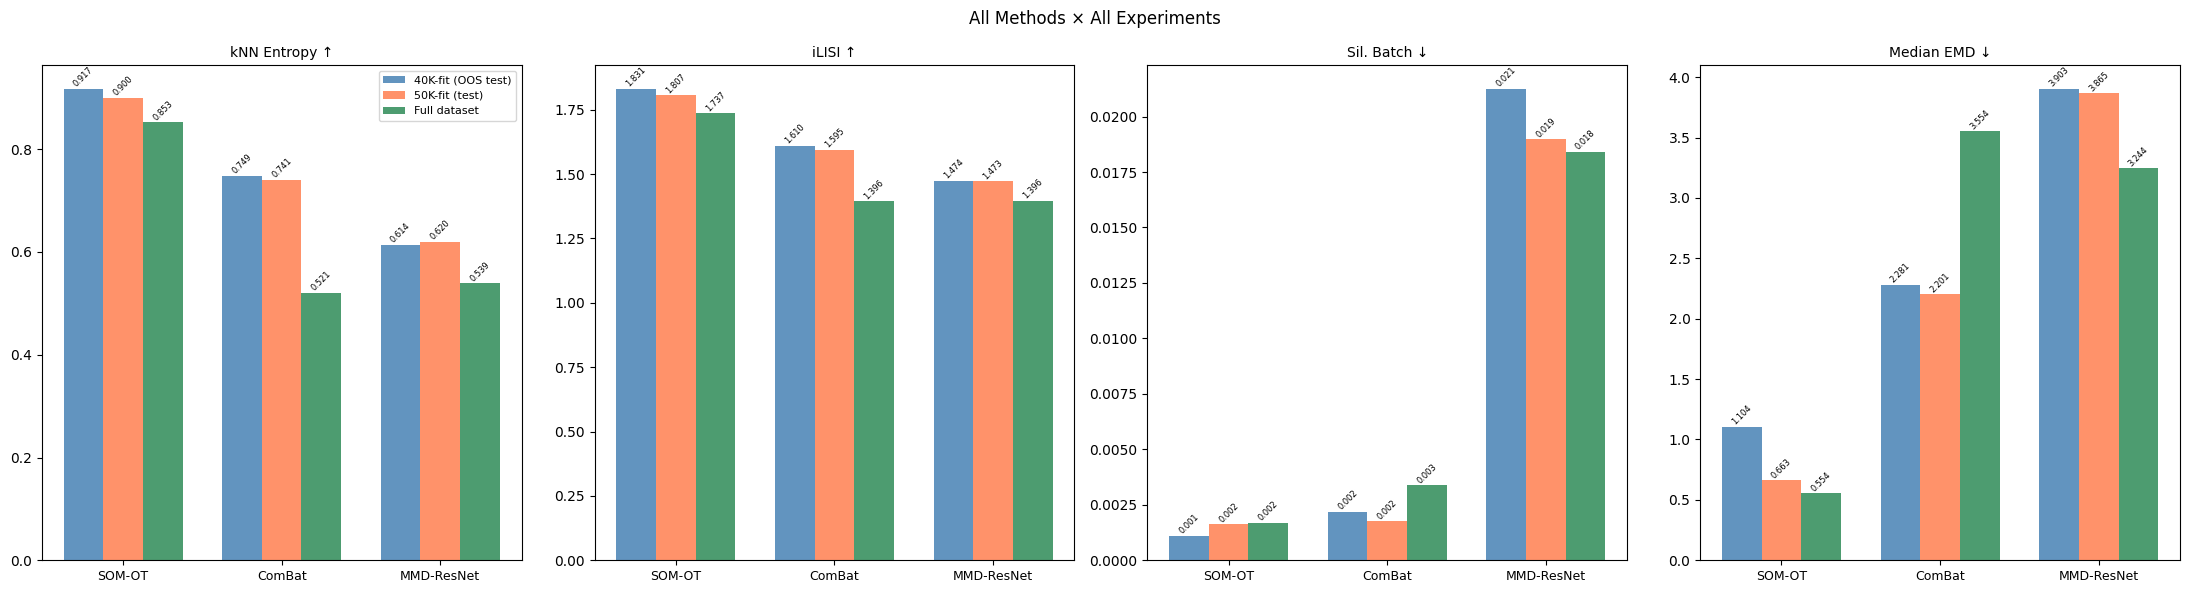

In [78]:
# ── Bar chart: all methods × all experiments ──
metric_keys = ['kNN Entropy ↑', 'iLISI ↑', 'Sil. Batch ↓', 'Median EMD ↓']
methods_all = ['SOM-OT', 'ComBat', 'MMD-ResNet']
exps = [
    ('Exp1a', 'Exp1a',  '40K-fit (OOS test)'),
    ('Exp1b', 'Exp1b',  '50K-fit (test)'),
    ('Exp2',  'Exp2',   'Full dataset'),
]
colors_exp = ['steelblue', 'coral', 'seagreen']

fig, axes = plt.subplots(1, len(metric_keys), figsize=(5.5 * len(metric_keys), 6))

for ax, mk in zip(axes, metric_keys):
    x = np.arange(len(methods_all))
    width = 0.25

    for i, (exp_prefix, exp_match, exp_label) in enumerate(exps):
        vals = []
        for m_name in methods_all:
            matching = [r for r in ALL_ROWS
                        if m_name in r['Setting']
                        and exp_match in r['Setting']
                        and 'Uncorrected' not in r['Setting']]
            vals.append(matching[0][mk] if matching else np.nan)

        offset = (i - 1) * width
        bars = ax.bar(x + offset, vals, width, label=exp_label, color=colors_exp[i], alpha=0.85)
        for bar in bars:
            h = bar.get_height()
            if not np.isnan(h):
                ax.text(bar.get_x() + bar.get_width()/2, h, f'{h:.3f}',
                        ha='center', va='bottom', fontsize=6, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels(methods_all, fontsize=9)
    ax.set_title(mk, fontsize=10)
    if ax == axes[0]:
        ax.legend(fontsize=8)

plt.suptitle('All Methods × All Experiments', fontsize=12)
plt.tight_layout()
plt.show()

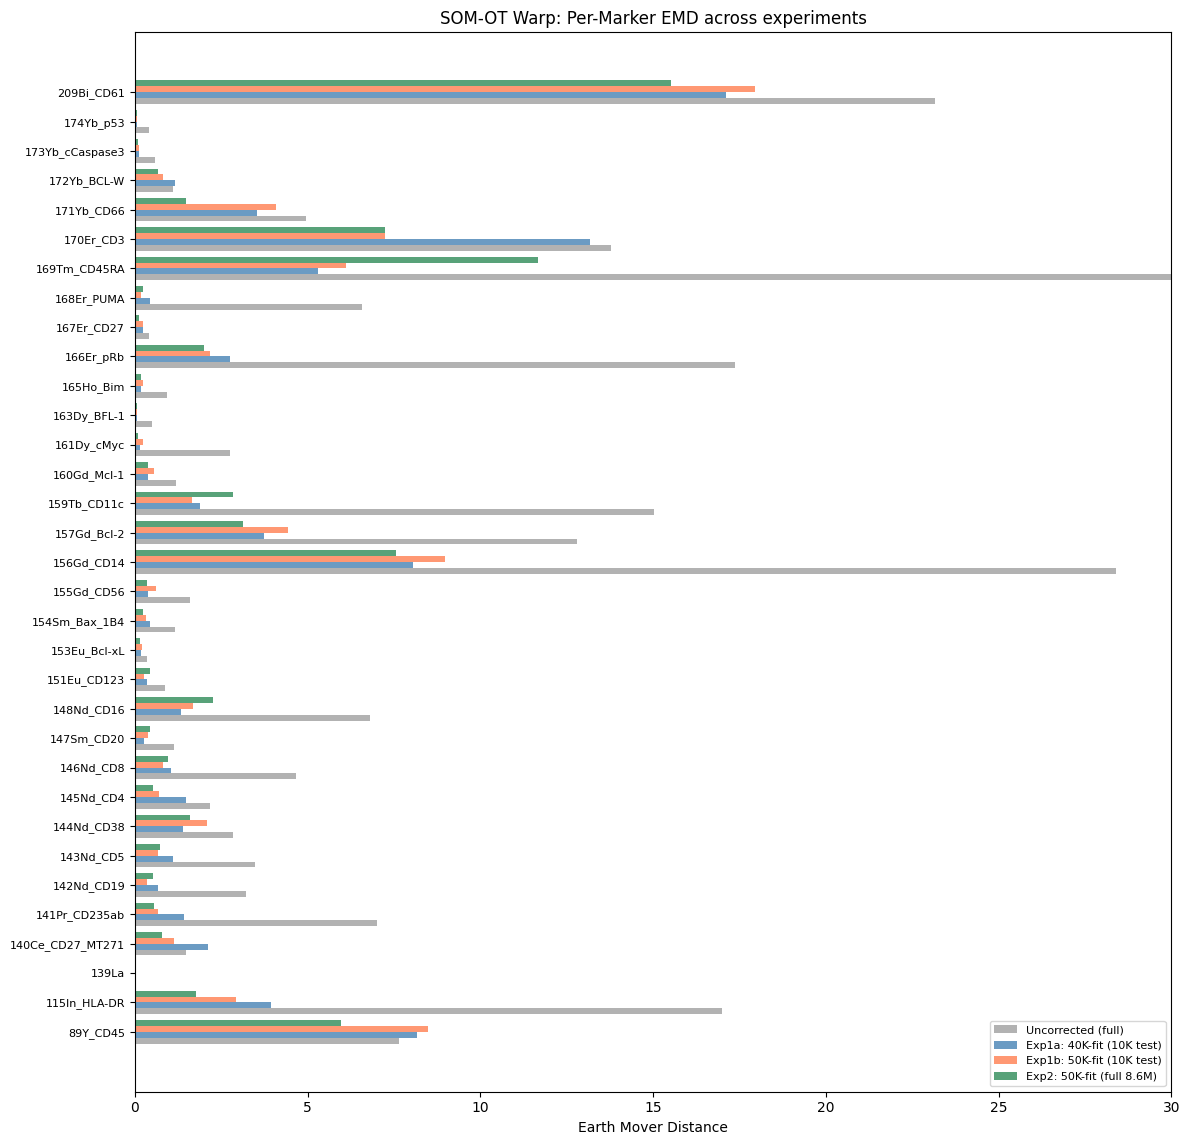

In [79]:
# ── Per-marker EMD: SOM-OT across 3 settings ──
fig, ax = plt.subplots(figsize=(12, max(8, len(markers) * 0.35)))

y_pos = np.arange(len(markers))
width = 0.2

# Uncorrected baseline — use full-dataset EMD (most representative)
emd_before = metrics_full_before['per_marker_emd']['per_marker']
vals_before = [emd_before.get(m, 0) for m in markers]
ax.barh(y_pos - 1.5*width, vals_before, width, label='Uncorrected (full)', color='gray', alpha=0.6)

# SOM-OT in each experiment
somot_exp_data = [
    (metrics_somot_1a,  'Exp1a: 40K-fit (10K test)',  'steelblue'),
    (metrics_somot_1b,  'Exp1b: 50K-fit (10K test)',   'coral'),
    (metrics_somot_2,   'Exp2: 50K-fit (full 8.6M)',   'seagreen'),
]

for i, (met, label, color) in enumerate(somot_exp_data):
    emd_after = met['per_marker_emd']['per_marker']
    vals = [emd_after.get(m, 0) for m in markers]
    ax.barh(y_pos + (i - 0.5) * width, vals, width, label=label, color=color, alpha=0.8)

ax.set_yticks(y_pos)
ax.set_yticklabels(markers, fontsize=8)
ax.set_xlabel('Earth Mover Distance')
ax.set_title('SOM-OT Warp: Per-Marker EMD across experiments')
ax.legend(fontsize=8, loc='lower right')
ax.set_xlim(0, min(30, max(vals_before) * 1.1))  # cap for readability
plt.tight_layout()
plt.show()

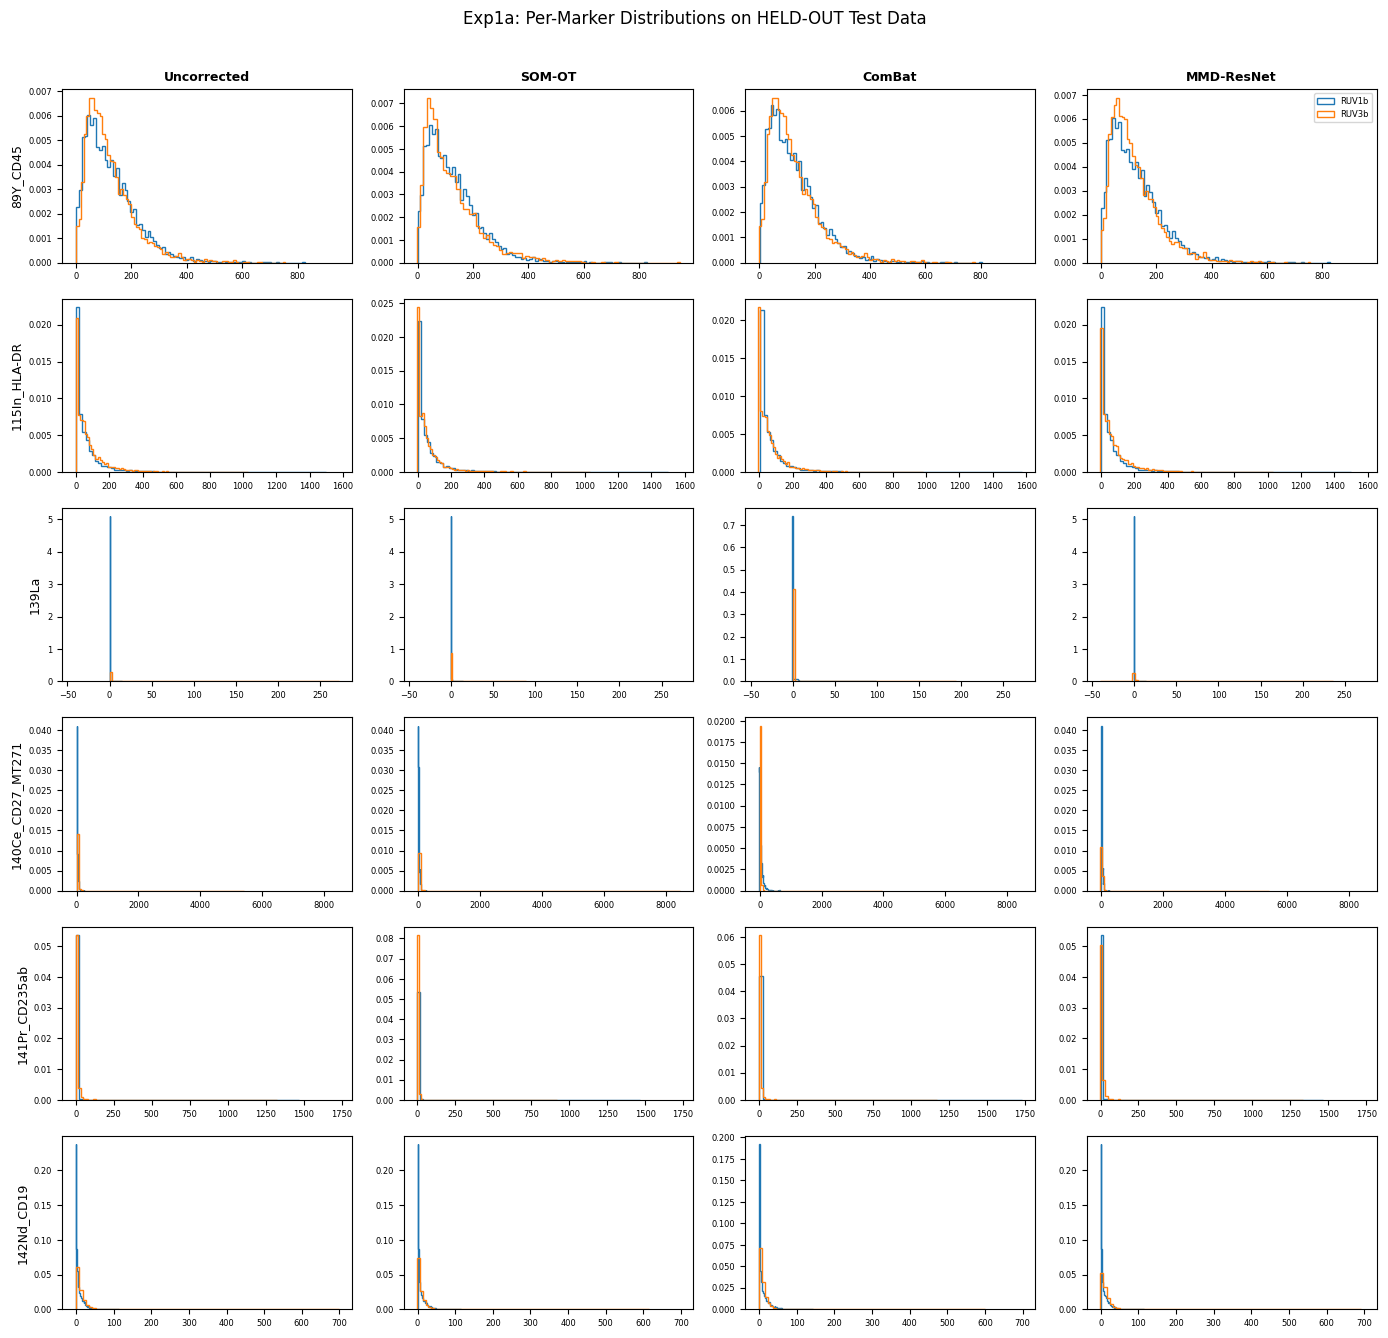

In [80]:
# ── Per-marker distribution overlay: Exp1a (test split) ──
n_show = min(6, len(markers))
show_markers = markers[:n_show]

col_data = [
    ('Uncorrected',  X_test,            y_batch_test),
    ('SOM-OT',       X_test_somot_1a,   y_batch_test),
    ('ComBat',       X_test_combat_1a,  y_batch_test),
    ('MMD-ResNet',   X_test_mmd_1a,     y_batch_test),
]

batches = np.unique(y_batch_test)
fig, axes = plt.subplots(n_show, len(col_data),
                         figsize=(3.5 * len(col_data), 2.2 * n_show),
                         sharex='row')

for col, (cname, Xm, yb) in enumerate(col_data):
    for row, mk in enumerate(show_markers):
        ax = axes[row, col]
        j = markers.index(mk)
        for b in batches:
            mask = yb == b
            ax.hist(Xm[mask, j], bins=80, density=True, histtype='step', label=b, linewidth=1)
        if row == 0: ax.set_title(cname, fontsize=9, fontweight='bold')
        if col == 0: ax.set_ylabel(mk, fontsize=9)
        if row == 0 and col == len(col_data) - 1: ax.legend(fontsize=6)
        ax.tick_params(labelsize=6)

plt.suptitle('Exp1a: Per-Marker Distributions on HELD-OUT Test Data', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

---
## UMAP: Out-of-sample test data (Exp 1a)

In [81]:
import umap
from sklearn.preprocessing import StandardScaler

n_umap = min(10000, len(X_test))
rng_umap = np.random.RandomState(42)
umap_idx = rng_umap.choice(len(X_test), n_umap, replace=False)
batch_umap = y_batch_test[umap_idx]
ct_umap    = y_ct_test[umap_idx]

umap_datasets = {
    'Uncorrected': X_test,
    'SOM-OT':      X_test_somot_1a,
    'ComBat':      X_test_combat_1a,
    'MMD-ResNet':  X_test_mmd_1a,
}

umap_embeddings = {}
for name, data in umap_datasets.items():
    print(f'UMAP: {name}...')
    Xs = StandardScaler().fit_transform(data[umap_idx])
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42, verbose=False)
    umap_embeddings[name] = reducer.fit_transform(Xs)
print('Done.')

UMAP: Uncorrected...
UMAP: SOM-OT...
UMAP: ComBat...
UMAP: MMD-ResNet...
Done.


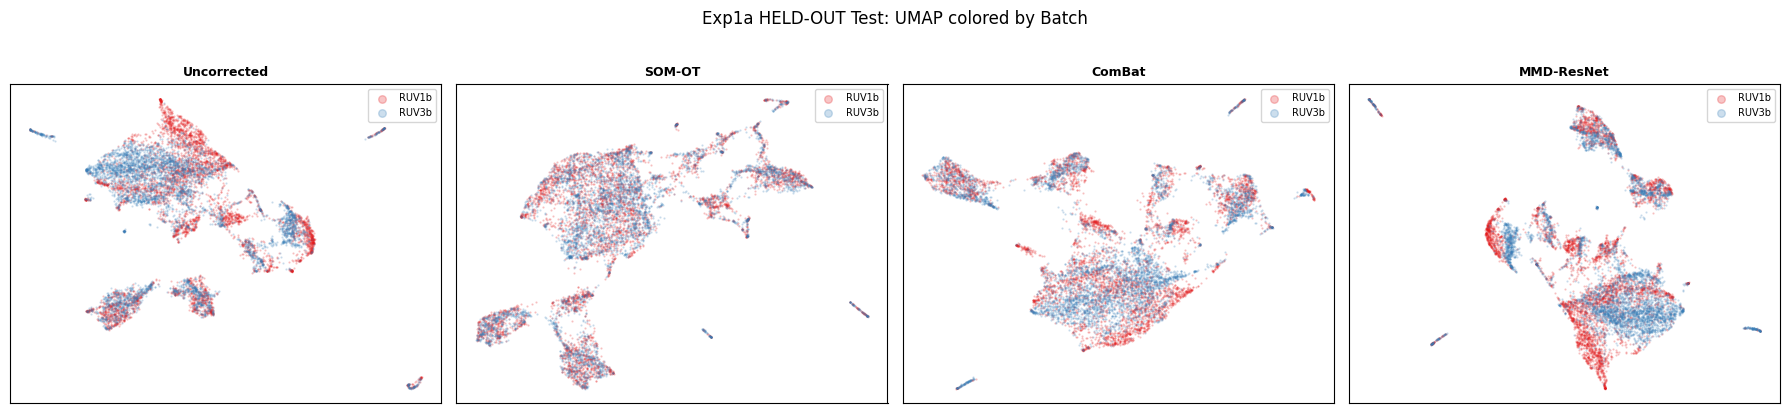

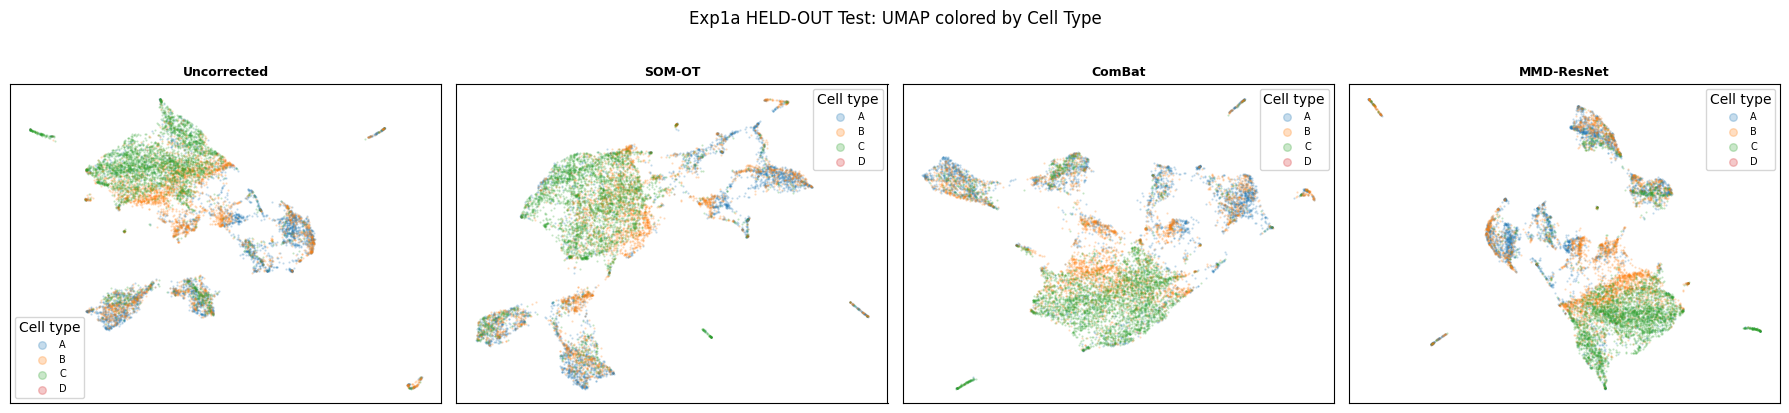

In [82]:
n_plots = len(umap_embeddings)

# Row 1: colored by batch
fig, axes = plt.subplots(1, n_plots, figsize=(4.5 * n_plots, 4))
if n_plots == 1: axes = [axes]
batch_colors = {b: plt.cm.Set1(i) for i, b in enumerate(np.unique(batch_umap))}
for ax, (name, emb) in zip(axes, umap_embeddings.items()):
    for b in np.unique(batch_umap):
        mask = batch_umap == b
        ax.scatter(emb[mask, 0], emb[mask, 1], s=0.3, alpha=0.25, label=b, color=batch_colors[b])
    ax.set_title(name, fontsize=9, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=10, fontsize=7)
plt.suptitle('Exp1a HELD-OUT Test: UMAP colored by Batch', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

# Row 2: colored by cell type
fig2, axes2 = plt.subplots(1, n_plots, figsize=(4.5 * n_plots, 4))
if n_plots == 1: axes2 = [axes2]
ct_colors = {ct: plt.cm.tab10(i) for i, ct in enumerate(sorted(np.unique(ct_umap)))}
for ax, (name, emb) in zip(axes2, umap_embeddings.items()):
    for ct in sorted(np.unique(ct_umap)):
        mask = ct_umap == ct
        ax.scatter(emb[mask, 0], emb[mask, 1], s=0.3, alpha=0.25, label=ct, color=ct_colors[ct])
    ax.set_title(name, fontsize=9, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=10, fontsize=7, title='Cell type')
plt.suptitle('Exp1a HELD-OUT Test: UMAP colored by Cell Type', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

---
## Save Results

In [83]:
OUT_DIR = REPO / 'results' / 'generalization'
OUT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(OUT_DIR / 'generalization_results.csv', index=False)
print(f'Results saved to {OUT_DIR / "generalization_results.csv"}')

# Save per-experiment detail JSONs
detail = {
    'exp1_test_before':     metrics_test_before,
    'exp1a_somot':          metrics_somot_1a,
    'exp1a_combat':         metrics_combat_1a,
    'exp1a_mmdresnet':      metrics_mmd_1a,
    'exp1b_somot':          metrics_somot_1b,
    'exp1b_combat':         metrics_combat_1b,
    'exp1b_mmdresnet':      metrics_mmd_1b,
    'exp2_full_before':     metrics_full_before,
    'exp2_somot':           metrics_somot_2,
    'exp2_combat':          metrics_combat_2,
    'exp2_mmdresnet':       metrics_mmd_2,
}
with open(OUT_DIR / 'generalization_detail.json', 'w') as f:
    json.dump(detail, f, indent=2, default=str)

print(f'Detail JSON saved to {OUT_DIR / "generalization_detail.json"}')

Results saved to <repo>/results/generalization/generalization_results.csv
Detail JSON saved to <repo>/results/generalization/generalization_detail.json
